In [2]:
from pathlib import Path
import pandas as pd
from PIL import Image
import imagehash
from collections import defaultdict

In [4]:
# CREAR INVENTARIO DE IMÁGENES

dataset_path = Path("../data/processed/")
splits = ["train", "test", "val"]

def crear_invetario_df(ruta) -> pd.DataFrame:
    archivos = []
    for split in splits:
        split_dir = ruta / split
        if not split_dir.exists():
            raise FileNotFoundError(
                f"No existe el directorio: {split_dir}"
            )

        for image_path in sorted(split_dir.rglob("*")):
                if (image_path.is_file()):
                     archivos.append({
                        "image_id": image_path.stem,
                        "relative_path": image_path,
                        "split": split,
                        "label": image_path.parent.name,
                        "extension": image_path.suffix.lower(),
                        "file_size_bytes": image_path.stat().st_size,
    })

    return pd.DataFrame(archivos)

df_inventario = crear_invetario_df(dataset_path)
df_inventario.head()

,image_id,relative_path,split,label,extension,file_size_bytes
0,03cheilitis05010422,..\data\processed\train\1. Enfeksiyonel\03chei...,train,1. Enfeksiyonel,.jpg,82514
1,03ContactDerm050127,..\data\processed\train\1. Enfeksiyonel\03Cont...,train,1. Enfeksiyonel,.jpg,102022
2,09cellulitis032706,..\data\processed\train\1. Enfeksiyonel\09cell...,train,1. Enfeksiyonel,.jpg,104199
3,09EczemaInfected062804,..\data\processed\train\1. Enfeksiyonel\09Ecze...,train,1. Enfeksiyonel,.jpg,74017
4,09EczemaInfected0628041,..\data\processed\train\1. Enfeksiyonel\09Ecze...,train,1. Enfeksiyonel,.jpg,78647


In [5]:
print("Total de imágenes:", len(df_inventario))

print("\nImágenes por subconjunto:")
print(df_inventario["split"].value_counts())

print("\nImágenes por clase:")
print(df_inventario["label"].value_counts())

Total de imágenes: 38761

Imágenes por subconjunto:
split
train    30910
test      3928
val       3923
Name: count, dtype: int64

Imágenes por clase:
label
5. Benign          13610
6. Malign           8479
1. Enfeksiyonel     7500
2. Ekzama           5088
3. Akne             2793
4. Pigment          1291
Name: count, dtype: int64


In [6]:
# CREAR ARCHIVO DE INVETARIO DE IMÁGENES
OUTPUT_DIR = Path("..") / "data" / "processed"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

df_inventario.to_csv(
    OUTPUT_DIR / "inventario_imagenes.csv",
    index=False,
)

Todas las imágenes son reconocidas y en formatos aceptados.
Existe una desvarianza en cuanto a las imágenes por clase.

In [7]:
# VERIFICAR QUE LAS IMÁGENES SE PUEDEN ABRIR

def verificar_imagen(ruta) -> pd.DataFrame:
    imagenes = []
    for split in splits :
        split_dir = ruta / split
        if not split_dir.exists():
            raise FileNotFoundError(
            f"No existe el directorio: {ruta}"
            )
        
        for image_path in sorted(split_dir.rglob("*")):
            if (image_path.is_file()):
                try:
                    with Image.open(image_path) as img:
                        img.verify()
                    with Image.open(image_path) as img:
                        img.load()
                        imagenes.append(f"OK: {image_path}")
                except Exception as e:
                    imagenes.append(f"ERROR: {image_path} está dañada o no es una imagen válida. ({e})")

        return pd.DataFrame(imagenes)
    
df_img = verificar_imagen(dataset_path)
print("Validación de imágenes realizada")


Validación de imágenes realizada


In [8]:
# CREAR ARCHIVO DE VALIDACIÓN DE IMÁGENES
OUTPUT_DIR = Path("..") / "data" / "processed"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

df_img.to_csv(
    OUTPUT_DIR / "validacion_imagenes.csv",
    index=False,
)

Se revisa csv, no se encuentra ninguna imagen dañada o que no se pueda abrir.

In [9]:
# ENCONTRAR IMÁGENES DUPLICADAS
hashes = defaultdict(list)
duplicados = []

for archivo in df_inventario["relative_path"]:
    try:
        with Image.open(archivo) as img:
            hash_actual = str(imagehash.phash(img))
            hashes[hash_actual].append(archivo)
    except Exception as e:
        print(f"Error al procesar {archivo}: {e}")
        
duplicados = {
    hash_img: rutas
    for hash_img, rutas in hashes.items()
    if len(rutas) > 1
}

if duplicados:
    print(f"Se encontraron {len(duplicados)} grupos de imágenes duplicadas\n")
else:
    print("\nNo se encontraron imágenes duplicadas.")



Se encontraron 7364 grupos de imágenes duplicadas



In [10]:
# Primeros 5 registros
for hash_img, rutas in list(duplicados.items())[:5]:
    print(f"\nHash: {hash_img}")
    for ruta in rutas:
        print(f"  {ruta}")


Hash: c8e997e02cdc6267
  ..\data\processed\train\1. Enfeksiyonel\03cheilitis05010422.jpg
  ..\data\processed\train\1. Enfeksiyonel\v-03cheilitis05010422.jpg

Hash: c1b9dfa1217582e6
  ..\data\processed\train\1. Enfeksiyonel\03ContactDerm050127.jpg
  ..\data\processed\train\1. Enfeksiyonel\t-03ContactDerm050127.jpg

Hash: d0bd6f02541fed12
  ..\data\processed\train\1. Enfeksiyonel\09PseudomonasFoll.jpg
  ..\data\processed\train\1. Enfeksiyonel\Pseudomonas-Folliculitis-1.jpg

Hash: 83d6bd4db60c992c
  ..\data\processed\train\1. Enfeksiyonel\0_1.jpg
  ..\data\processed\train\1. Enfeksiyonel\6_266.jpg

Hash: def4f850a277f010
  ..\data\processed\train\1. Enfeksiyonel\0_10.jpg
  ..\data\processed\val\1. Enfeksiyonel\6_97.jpg


Se revisan algunas copias y, junto al grupo, se decide eliminar esas copias exactas para no sesgar datos o que el modelo los memorice.

In [11]:
# ELIMINAR IMÁGENES DUPLICADAS, SE ELIMINA LA SEGUNDA IMAGEN DE CADA CONJUNTO
eliminar = []
eliminados = 0
errores = []

for hash_img, rutas in duplicados.items():
    eliminar.extend(rutas[1:])

for ruta in eliminar:
    try:
        archivo = Path(ruta)
        if archivo.is_file():
            archivo.unlink()
            eliminados += 1
    except OSError as e:
        errores.append(f"Se ha producido un error al eliminar: {ruta} \n{e}")

print(f"Total archivos eliminados: {eliminados}")
if errores:
    print(f"Errores: {len(errores)}")

Total archivos eliminados: 7981


El número de imágenes duplicadas es mayor ya que algunos grupos contaban con más de una copia exacta de cada imagen.

In [16]:
# NUEVOS VALORES DESPUÉS DE ELIMINAR DUPLICADOS
df_inventario_limpio = crear_invetario_df(dataset_path)
print("Total de imágenes:", len(df_inventario_limpio))

print("\nImágenes por subconjunto:")
print(df_inventario_limpio["split"].value_counts())

print("\nImágenes por clase:")
print(df_inventario_limpio["label"].value_counts())


Total de imágenes: 30780

Imágenes por subconjunto:
split
train    25918
test      2506
val       2356
Name: count, dtype: int64

Imágenes por clase:
label
5. Benign          11835
6. Malign           8374
1. Enfeksiyonel     4185
2. Ekzama           2731
3. Akne             2434
4. Pigment          1221
Name: count, dtype: int64


In [19]:
# CREAR ARCHIVO DE INVENTARIO DE IMÁGENES SIN DUPLICADOS
OUTPUT_DIR = Path("..") / "data" / "processed"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

df_inventario_limpio.to_csv(
    OUTPUT_DIR / "inventario_imagenes_unicas.csv",
    index=False,
)

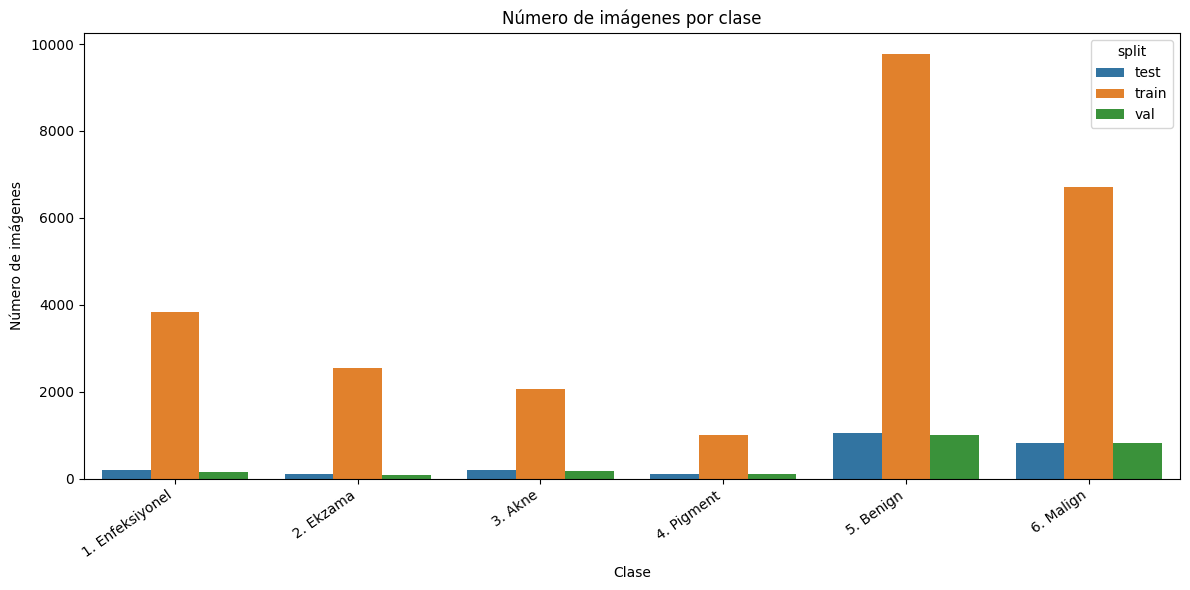

In [13]:
# EDA
import matplotlib.pyplot as plt
import seaborn as sns

clases = (
    df_inventario_limpio.groupby(["split", "label"])
    .size()
    .reset_index(name="images")
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=clases,
    x="label",
    y="images",
    hue="split",
)

plt.title("Número de imágenes por clase")
plt.xlabel("Clase")
plt.ylabel("Número de imágenes")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

Visualmente se puede apreciar la diferencia en cuanto a números de imágenes de las clases 'Benigno' y 'Maligno'.